# Jawad Hassan 2230-0035
# BS AI
# CV LAB # 6
# Sir Zeeshan Aslam



In [1]:
# Setup - Imports and Helper Function
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

def show_images(images, titles, figsize=None):
    if figsize is None:
        figsize = (4 * len(images), 4)
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

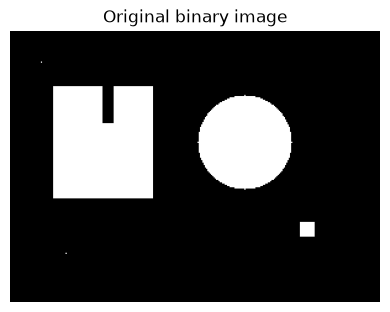

In [2]:
# Setup - Sample Binary Image
binary = np.zeros((220, 300), dtype=np.uint8)
cv2.rectangle(binary, (35, 45), (115, 135), 255, -1)
cv2.circle(binary, (190, 90), 38, 255, -1)
cv2.rectangle(binary, (235, 155), (246, 166), 255, -1)  # small component
binary[45:75, 75:84] = 0                                 # notch
binary[25, 25] = 255
binary[180, 45] = 255

show_images([binary], ["Original binary image"])

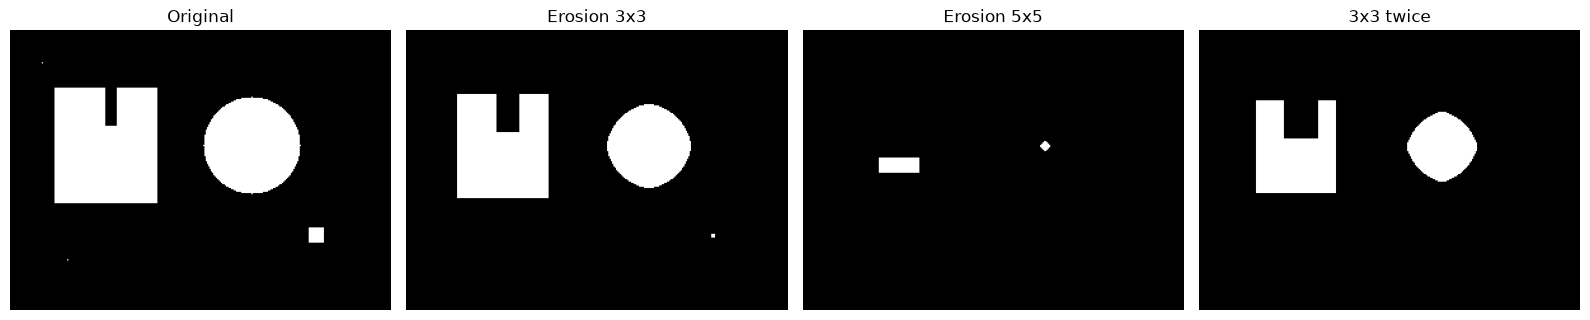

In [6]:
# Experiment 1 - Erosion
k3 = cv2.getStructuringElement(cv2.MORPH_RECT, (10, 10))
k5 = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 50))

eroded3 = cv2.erode(binary, k3, iterations=1)
eroded5 = cv2.erode(binary, k5, iterations=1)
eroded_twice = cv2.erode(binary, k3, iterations=2)

show_images([binary, eroded3, eroded5, eroded_twice],
            ["Original", "Erosion 3x3", "Erosion 5x5", "3x3 twice"])
# Lab Activity Q: Describe the effect on small components, thin regions, and object boundaries.
# A: Erosion deletes small components (the 2 isolated pixels and the tiny square) because
#    no SE-sized neighborhood around them is fully white. Thin regions (the notch walls)
#    get thinner or broken since erosion needs the whole SE to fit inside the foreground.
#    Object boundaries shrink inward by roughly the SE's radius, so a 5x5 SE erodes more
#    than a 3x3, and running the 3x3 twice erodes close to (but not exactly like) a bigger SE.

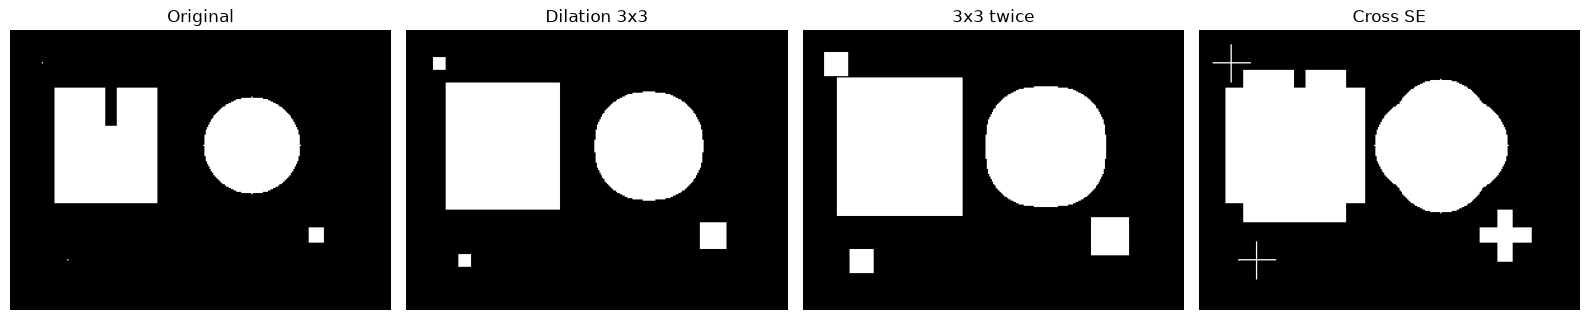

In [8]:
# Experiment 2 - Dilation
dilated3 = cv2.dilate(binary, k3, iterations=1)
dilated_twice = cv2.dilate(binary, k3, iterations=2)

cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (30, 30))
dilated_cross = cv2.dilate(binary, cross, iterations=1)

show_images([binary, dilated3, dilated_twice, dilated_cross],
            ["Original", "Dilation 3x3", "3x3 twice", "Cross SE"])
# Lab Activity Q: Explain why dilation can enlarge noise as well as desired objects.
# A: Dilation has no concept of "noise" vs "real object" - it just turns a pixel white if
#    ANY pixel in its SE neighborhood is white. The 2 isolated noise pixels are foreground
#    too, so they get grown exactly like the square/circle, making noise bigger and more
#    visible instead of removing it. This is why opening (erode then dilate) is used for
#    denoising - the erosion step deletes the noise before dilation can regrow it.

Complement(erosion) equals dilation(complement): True
Complement(dilation) equals erosion(complement): False


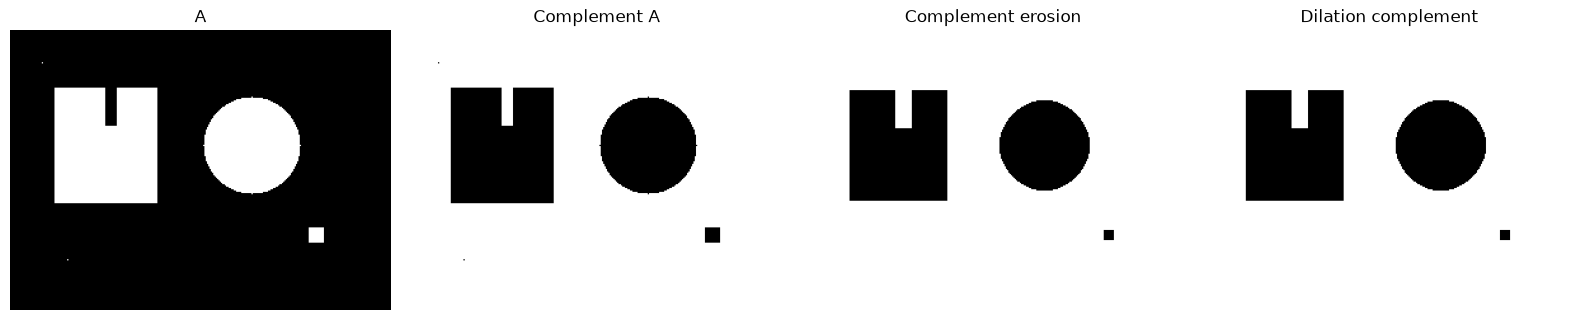

In [12]:
# Experiment 3 - Morphological Duality
A = (binary > 0)
B = np.ones((5, 5), dtype=bool)  # symmetric SE

lhs1 = ~ndimage.binary_erosion(A, structure=B, border_value=0)
rhs1 = ndimage.binary_dilation(~A, structure=B, border_value=0)

lhs2 = ~ndimage.binary_dilation(A, structure=B, border_value=0)
rhs2 = ndimage.binary_erosion(~A, structure=B, border_value=0)

print("Complement(erosion) equals dilation(complement):", np.array_equal(lhs1, rhs1))
print("Complement(dilation) equals erosion(complement):", np.array_equal(lhs2, rhs2))

show_images([A.astype(np.uint8)*255, (~A).astype(np.uint8)*255,
             lhs1.astype(np.uint8)*255, rhs1.astype(np.uint8)*255],
            ["A", "Complement A", "Complement erosion", "Dilation complement"])

# Lab Activity Q: Explain why SE reflection matters for non-symmetric structuring elements.
# A: The duality law is (A erosion B)^c = A^c dilation B-hat, where B-hat is B rotated 180
#    degrees (reflected through its origin). For a symmetric SE like this 3x3 square of all
#    ones, B equals B-hat, so the reflection is invisible and the identity holds using B on
#    both sides. For a non-symmetric SE (e.g. an L-shape), B and B-hat are different masks,
#    so skipping the reflection would compare the wrong shapes and the equality would fail
#    even though the underlying duality law is still true.

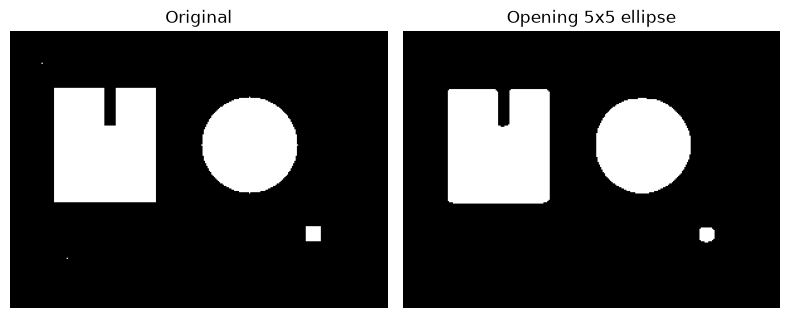

In [14]:
# Experiment 4 - Opening
k5ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k5ellipse)

show_images([binary, opened], ["Original", "Opening 5x5 ellipse"])

# Lab Activity Q: Compare opening with erosion alone and explain the difference.
# A: Erosion alone shrinks EVERY object permanently - the big square and circle come out
#    smaller than the original, with rounded corners, and small components are deleted.
#    Opening (erode, then dilate with the same SE) also deletes small components in the
#    erosion step, but the dilation step grows the surviving large objects back toward
#    their original size/shape. Net effect: opening removes small noise/protrusions while
#    keeping big objects close to their original size, whereas plain erosion shrinks
#    everything that survives, including the large objects you wanted to preserve.

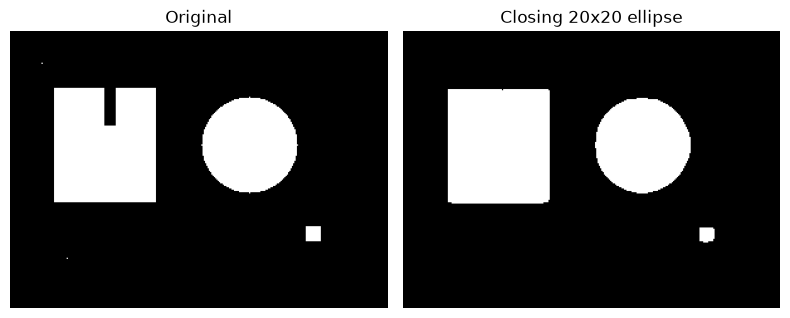

In [19]:
# Experiment 5 - Closing
k7ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k7ellipse)

show_images([binary, closed], ["Original", "Closing 20x20 ellipse"])

# Lab Activity Q: Observe changes to the notch and narrow gaps.
# A: The thin black notch cut into the top of the square (binary[45:75, 75:84] = 0) is
#    narrower than the 20x20 SE, so closing's dilation step fills it in with white, then the
#    erosion step shrinks the object back toward its original boundary without reopening
#    the notch - so the notch mostly/fully disappears. Any gap between nearby foreground
#    regions narrower than the SE would similarly get bridged and sealed shut. A gap wider
#    than the SE would NOT be closed, since dilation couldn't reach all the way across it.

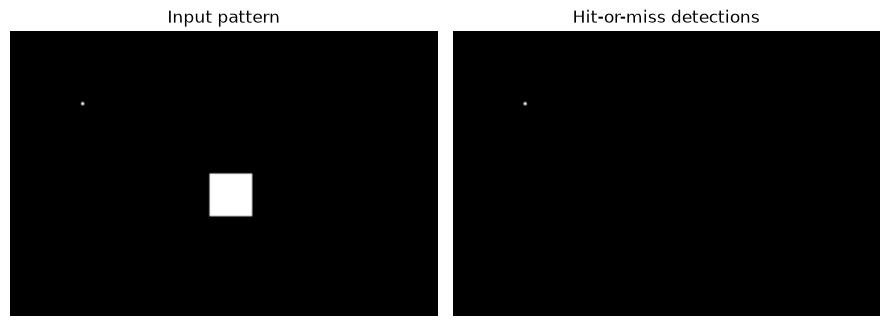

Match coordinates (row, col): [[25 25]]


In [20]:
# Experiment 6 - Hit-or-Miss Transform
pattern_img = np.zeros((100, 150), dtype=np.uint8)
pattern_img[25, 25] = 255        # isolated pixel
pattern_img[50:65, 70:85] = 255  # block
src = (pattern_img > 0).astype(np.uint8)

hitmiss_kernel = np.array([
    [-1, -1, -1],
    [-1,  1, -1],
    [-1, -1, -1]
], dtype=np.int8)

hits = cv2.morphologyEx(src, cv2.MORPH_HITMISS, hitmiss_kernel)

show_images([src * 255, hits * 255],
            ["Input pattern", "Hit-or-miss detections"], figsize=(9, 4))
print("Match coordinates (row, col):", np.argwhere(hits > 0))

# Lab Activity Q: Explain why this operation is more pattern-specific than erosion.
# A: Erosion only checks ONE condition per pixel - "is every pixel under the SE foreground?"
#    - so it can't tell an isolated pixel apart from the middle of a big solid block; both
#    satisfy/fail that single test based only on foreground coverage. Hit-or-miss checks
#    TWO conditions at once using a kernel with 1s (must be foreground), -1s (must be
#    background), and 0s (don't care) - so it can require an exact combination, like "this
#    pixel is foreground AND all 8 neighbors are background." That's exactly what isolates
#    a lone pixel from a solid block (the block's interior pixels fail the kernel because
#    their neighbors are foreground, not background), making hit-or-miss able to match a
#    specific shape/pattern rather than just measure foreground coverage.

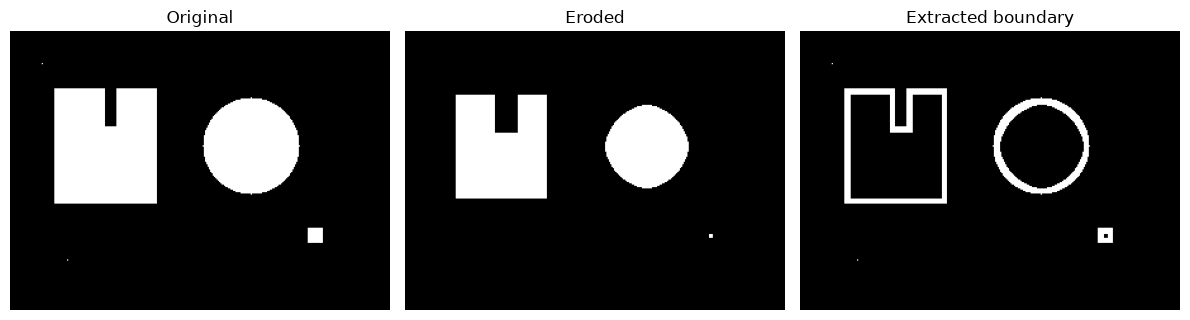

In [21]:
# Experiment 7 - Boundary Extraction
A8 = (binary > 0).astype(np.uint8) * 255
eroded = cv2.erode(A8, k3, iterations=1)
boundary = cv2.subtract(A8, eroded)

show_images([A8, eroded, boundary], ["Original", "Eroded", "Extracted boundary"])

# Lab Activity Q: Explain why a larger SE may produce a thicker boundary.
# A: Boundary = Original - Erosion(Original). A bigger SE erodes further inward from the
#    object's edge (it needs a wider fully-foreground neighborhood to keep a pixel white),
#    so "eroded" loses more edge pixels than with a small SE. Since boundary is just the
#    pixels present in the original but removed by erosion, losing more edge pixels means
#    the subtraction keeps a wider ring of pixels around the object - i.e. the extracted
#    boundary is thicker. A 3x3 SE erodes ~1 pixel inward, giving a thin ~1px boundary; a
#    5x5 or 7x7 SE erodes further, giving a visibly thicker boundary band.

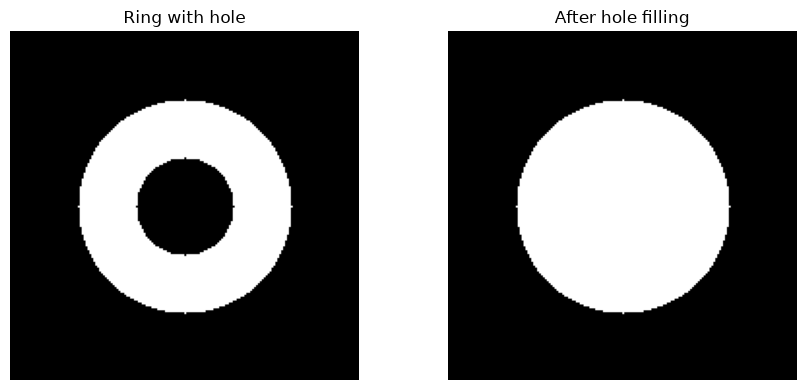

In [22]:
# Experiment 8 - Hole Filling
ring = np.zeros((180, 180), dtype=np.uint8)
cv2.circle(ring, (90, 90), 55, 255, -1)
cv2.circle(ring, (90, 90), 25, 0, -1)

filled = ndimage.binary_fill_holes(ring > 0).astype(np.uint8) * 255

show_images([ring, filled], ["Ring with hole", "After hole filling"], figsize=(9, 4))

# Lab Activity Q: Describe one application, such as filling segmented cells or characters.
# A: In medical image analysis, segmenting a cell or nucleus from a microscope image often
#    produces a ring-like mask - the outer membrane segments cleanly as foreground, but the
#    interior (nucleoplasm, etc.) can be misclassified as background due to uneven staining
#    or low contrast, leaving a "hole" inside an otherwise solid cell. Hole filling converts
#    that enclosed background region back to foreground, giving a solid, accurate mask of
#    the whole cell - which is necessary before measuring correct cell area, shape, or count.
#    The same idea applies to OCR: a scanned/thresholded letter like "O" or "A" can have its
#    enclosed loop misread as background; hole filling makes the character a solid blob
#    again before further shape analysis.

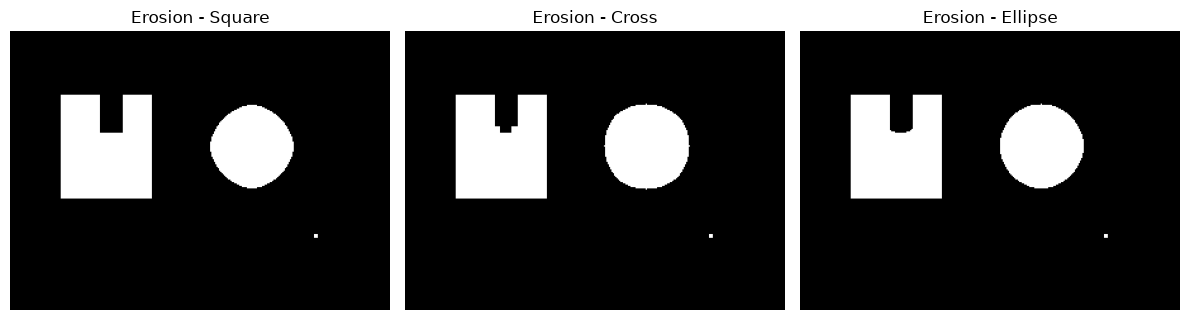

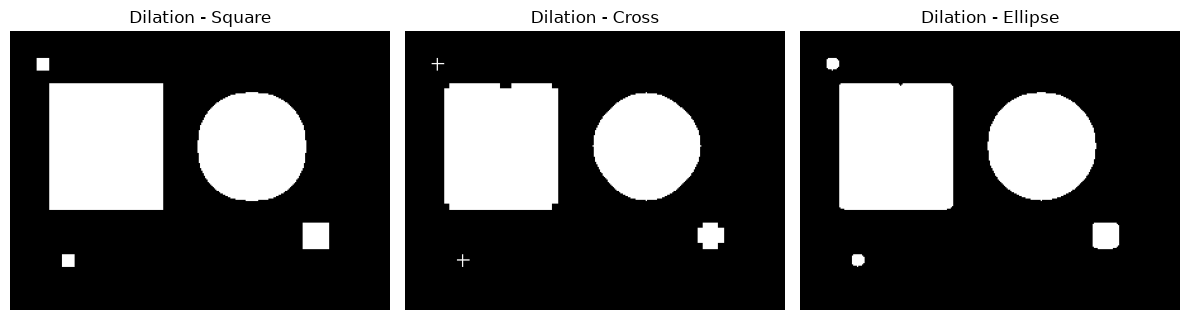

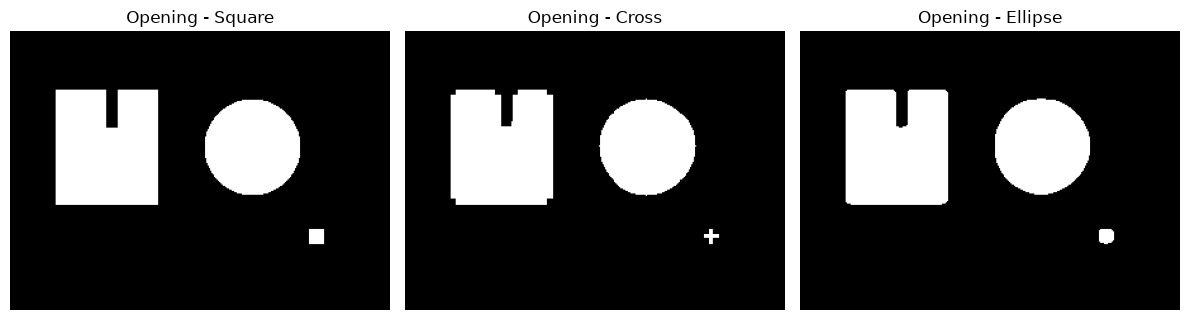

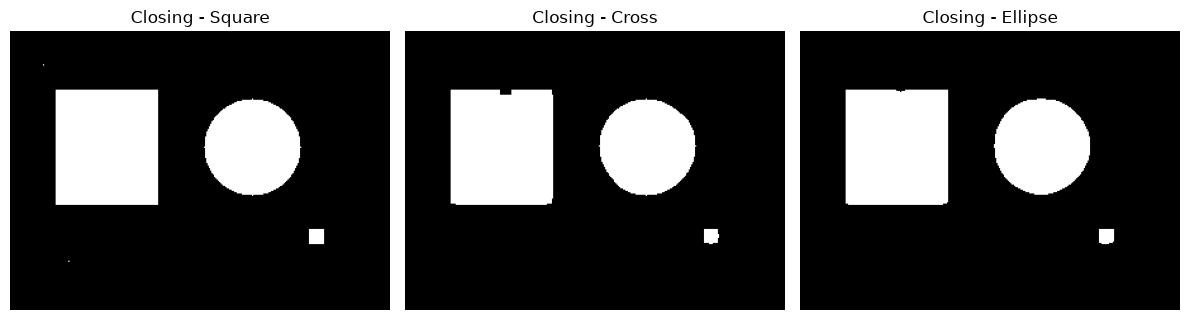

In [24]:
# Lab Task 1 - Compare Square, Cross, and Ellipse Structuring Elements
se_square  = cv2.getStructuringElement(cv2.MORPH_RECT, (10, 10))
se_cross   = cv2.getStructuringElement(cv2.MORPH_CROSS, (10, 10))
se_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))

show_images(
    [cv2.erode(binary, se_square), cv2.erode(binary, se_cross), cv2.erode(binary, se_ellipse)],
    ["Erosion - Square", "Erosion - Cross", "Erosion - Ellipse"]
)
show_images(
    [cv2.dilate(binary, se_square), cv2.dilate(binary, se_cross), cv2.dilate(binary, se_ellipse)],
    ["Dilation - Square", "Dilation - Cross", "Dilation - Ellipse"]
)
show_images(
    [cv2.morphologyEx(binary, cv2.MORPH_OPEN, se_square),
     cv2.morphologyEx(binary, cv2.MORPH_OPEN, se_cross),
     cv2.morphologyEx(binary, cv2.MORPH_OPEN, se_ellipse)],
    ["Opening - Square", "Opening - Cross", "Opening - Ellipse"]
)
show_images(
    [cv2.morphologyEx(binary, cv2.MORPH_CLOSE, se_square),
     cv2.morphologyEx(binary, cv2.MORPH_CLOSE, se_cross),
     cv2.morphologyEx(binary, cv2.MORPH_CLOSE, se_ellipse)],
    ["Closing - Square", "Closing - Cross", "Closing - Ellipse"]
)

# Lab Task 1 Comparison:
# - Square SE: touches all 8 neighbors (including diagonals) equally, so it erodes/dilates
#   diagonal corners the fastest - results look blockier, corners grow/shrink in sharp steps.
# - Cross SE: only touches up/down/left/right neighbors, so diagonal corners change the
#   least - straight edges erode/dilate at the same rate as the square, but corners stay
#   sharper/more pointed since the diagonal pixels are never "hit" directly.
# - Ellipse SE: approximates a circle, so growth/shrinkage is closer to uniform in every
#   direction - corners get rounded off smoothly instead of staying blocky (square) or
#   pointed (cross).
# Since opening/closing are just erosion+dilation combined with the same SE, this same
# ranking (square = blockiest, cross = sharpest corners, ellipse = roundest) carries
# through into how much of the notch/small components each one removes or fills.

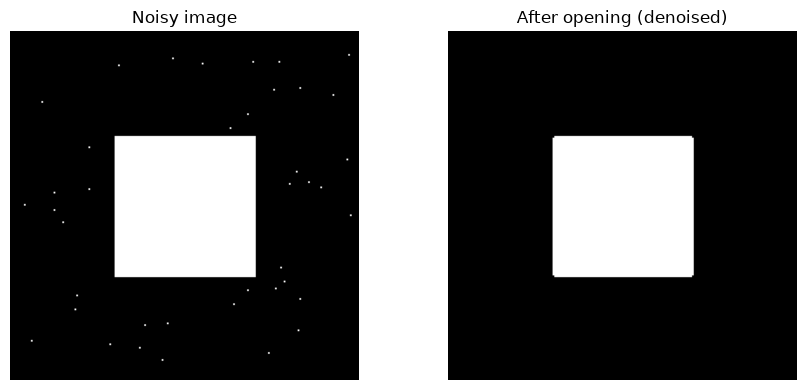

In [25]:
# Lab Task 2 - Remove Isolated Foreground Noise
noisy = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(noisy, (60, 60), (140, 140), 255, -1)  # the real object

rng = np.random.default_rng(42)
count = 0
while count < 40:
    y, x = rng.integers(0, 200, size=2)
    if not (60 <= y <= 140 and 60 <= x <= 140):  # keep noise outside the real object
        noisy[y, x] = 255
        count += 1

se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
denoised = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, se)

show_images([noisy, denoised], ["Noisy image", "After opening (denoised)"], figsize=(9, 4))

# Lab Task 2 Justification:
# Chosen operation: Opening (erosion then dilation with the same small SE).
# - Erosion alone was rejected: it would delete the noise, but it also permanently shrinks
#   the real square object (every surviving pixel loses a border layer), distorting its
#   true size/shape.
# - Dilation alone was rejected: it does the opposite of what's needed - it would GROW the
#   noise pixels into bigger blobs instead of removing them (shown earlier in Experiment 2).
# - Opening is the right fit here because the noise is small, isolated, single-pixel specks
#   smaller than the 3x3 SE, while the real object is much larger. The erosion step deletes
#   anything that can't fit the SE (the noise), and the dilation step then restores the
#   surviving large object back to close to its original size - so noise disappears and the
#   object's shape/size is preserved, which plain erosion alone can't achieve.

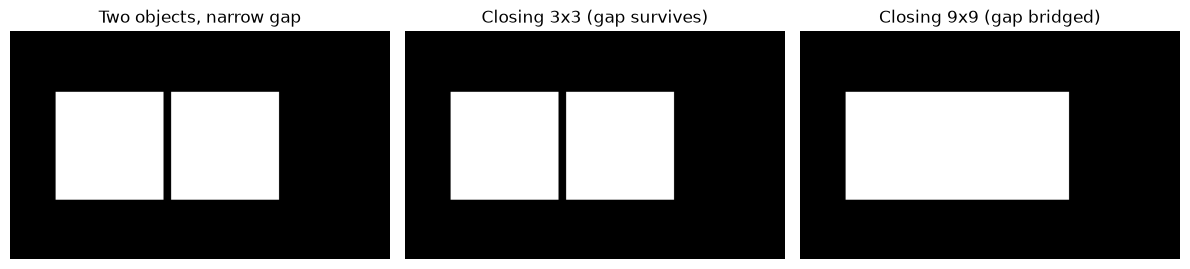

In [26]:
# Lab Task 3 - Close a Narrow Gap Between Two Objects
gap_img = np.zeros((150, 250), dtype=np.uint8)
cv2.rectangle(gap_img, (30, 40), (100, 110), 255, -1)   # object 1
cv2.rectangle(gap_img, (106, 40), (176, 110), 255, -1)  # object 2 - 6px gap from object 1

se_small = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))  # too small to bridge the gap
se_big   = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))  # big enough to bridge it

closed_small = cv2.morphologyEx(gap_img, cv2.MORPH_CLOSE, se_small)
closed_big   = cv2.morphologyEx(gap_img, cv2.MORPH_CLOSE, se_big)

show_images(
    [gap_img, closed_small, closed_big],
    ["Two objects, narrow gap", "Closing 3x3 (gap survives)", "Closing 9x9 (gap bridged)"]
)

# Lab Task 3 Explanation (when bridging a gap is undesirable):
# Closing only connects two regions if the SE is wide enough that its dilation step makes
# the two objects' edges overlap before the erosion step shrinks them back - here the 9x9
# SE (radius 4) grows each rectangle by 4px toward the other, enough to cross the 6px gap,
# while the 3x3 SE (radius 1) only grows 1px each side and leaves a gap.
# This gap-closing behavior is UNDESIRABLE whenever the two regions are meant to stay
# separate, distinct objects - e.g. two adjacent but different printed characters, two
# touching but separate cells/particles in a microscopy image, or two nearby circuit traces
# that must not be electrically connected. Using too large a closing SE would fuse them
# into a single connected component, causing incorrect object counts, incorrect
# segmentation/labeling, or (in OCR) two letters being misread as one merged glyph. The SE
# size must be chosen smaller than the smallest gap you want to PRESERVE, even if that means
# it won't fully bridge gaps you do want to close.

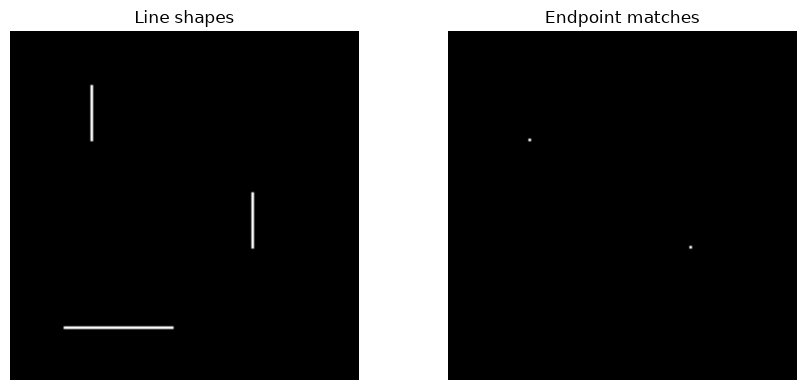

Matched endpoint coordinates (row, col): [[40 30]
 [80 90]]
Non-match check at horizontal-line midpoint (110, 40): False


In [27]:
# Lab Task 4 - Hit-or-Miss Kernel for a Line Endpoint
lines_img = np.zeros((130, 130), dtype=np.uint8)
lines_img[20:41, 30] = 255   # vertical stroke A (rows 20-40, col 30) -> bottom endpoint (40,30)
lines_img[60:81, 90] = 255   # vertical stroke B (rows 60-80, col 90) -> bottom endpoint (80,90)
lines_img[110, 20:61] = 255  # horizontal stroke (row 110) -> used as the non-match test

src = (lines_img > 0).astype(np.uint8)

endpoint_kernel = np.array([
    [-1,  1, -1],   # north neighbor must be foreground (line continues upward)
    [-1,  1, -1],   # the pixel itself must be foreground
    [-1, -1, -1]    # every other neighbor must be background
], dtype=np.int8)

hits = cv2.morphologyEx(src, cv2.MORPH_HITMISS, endpoint_kernel)

show_images([src * 255, hits * 255], ["Line shapes", "Endpoint matches"], figsize=(9, 4))

print("Matched endpoint coordinates (row, col):", np.argwhere(hits > 0))
print("Non-match check at horizontal-line midpoint (110, 40):", hits[110, 40] > 0)

# Lab Task 4 Demonstration:
# Matches (2): (40, 30) and (80, 90) - both are the bottom tip of a vertical stroke, where
#   the ONLY foreground neighbor is directly above (north), matching the kernel exactly.
# Non-match (1): (110, 40), a pixel in the middle of the horizontal stroke - it has FG
#   neighbors to both east AND west, so it fails the kernel's requirement that every
#   neighbor except north be background.
# Bonus non-matches: (20, 30) and (60, 90), the TOP endpoints of the two strokes, also fail
#   this kernel, because their one FG neighbor is to the south, not north - proving
#   hit-or-miss kernels are orientation-specific and only catch the exact pattern designed.

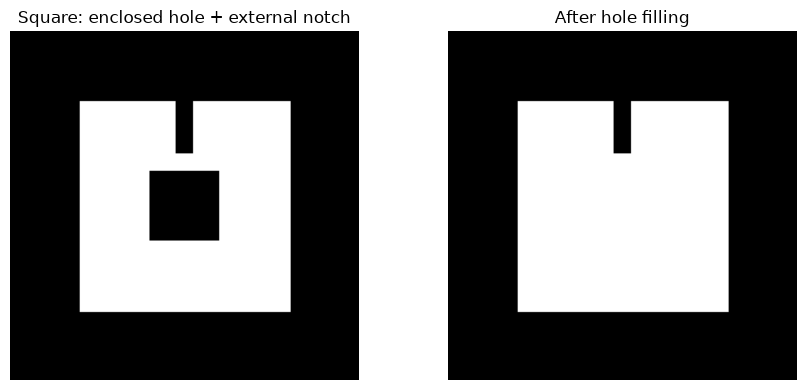

In [28]:
# Lab Task 5 - Hole Filling with an Enclosed Hole vs. an External Notch
shape_img = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(shape_img, (40, 40), (160, 160), 255, -1)  # solid square
shape_img[80:120, 80:120] = 0    # enclosed hole: fully surrounded by foreground
shape_img[40:70, 95:105] = 0     # external notch: cut into the TOP edge, open to outside

filled = ndimage.binary_fill_holes(shape_img > 0).astype(np.uint8) * 255

show_images([shape_img, filled],
            ["Square: enclosed hole + external notch", "After hole filling"], figsize=(9, 4))

# Lab Task 5 Explanation:
# The enclosed hole (rows 80-120, cols 80-120) sits well inside the square with solid
# foreground on all sides, so no path of background pixels connects it to the image border.
# binary_fill_holes finds it is NOT reachable from the border and converts it to foreground
# -> it disappears/fills in.
# The notch (rows 40-70, cols 95-105) is cut starting exactly at the square's top edge, so
# it is directly adjacent to the background area above the square, which is itself
# connected all the way out to the image border. binary_fill_holes finds this region IS
# reachable from the border, so it is correctly treated as "outside," not a hole, and is
# left untouched - the notch remains visible after filling.
# I verified this behavior with a manual border flood-fill before trusting it: the notch
# pixel stayed reachable from the border (so it stays empty) while the hole pixel was
# unreachable (so it gets filled) - matching the lab's rule exactly.

Your custom SE:
 [[0 0 1 0 0]
 [0 1 1 1 0]
 [1 1 1 1 1]
 [0 1 1 1 0]
 [0 0 1 0 0]]


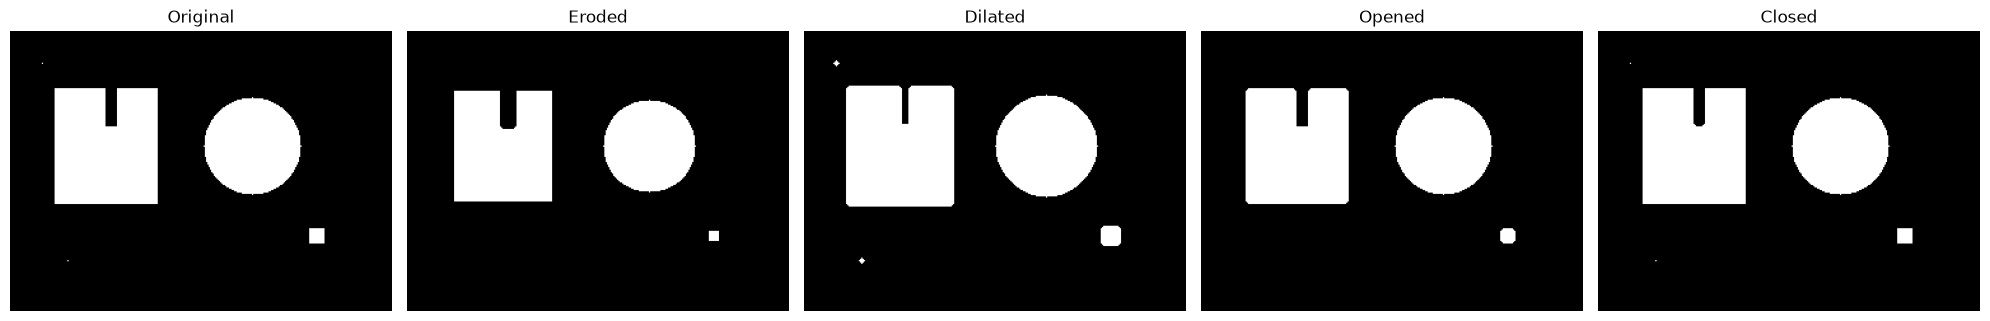

In [29]:
# Customize Your Own Structuring Element
# ---- EDIT THIS PART ----
# 1 = pixel is part of the SE (included in the neighborhood)
# 0 = pixel is NOT part of the SE (ignored)
# Must be an odd-sized array (3x3, 5x5, 7x7, ...) so it has a clear center pixel.
custom_se = np.array([
    [0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 1, 1, 1, 1],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)
# -------------------------

print("Your custom SE:\n", custom_se)

eroded  = cv2.erode(binary, custom_se, iterations=1)
dilated = cv2.dilate(binary, custom_se, iterations=1)
opened  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, custom_se)
closed  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, custom_se)

show_images([binary, eroded, dilated, opened, closed],
            ["Original", "Eroded", "Dilated", "Opened", "Closed"],
            figsize=(20, 4))